# Práctica 2: Reducción de dimensiones con PCA, Sammon y Autocodificadores

**Instituto Politécnico Nacional, Escuela Superior de Cómputo (ESCOM)**
**Asignatura:** Analítica y Visualización de Datos
**Profesor:** Ituriel Enrique Flores Estrada
**Equipo:** Melanie, Magaly, Ricardo y Santiago

**Conjunto de datos:** Breast Cancer Wisconsin (Diagnostic).

**Objetivo:** proyectar los datos a 3 dimensiones con PCA, Sammon, Sammon sobre PCA y un autocodificador no lineal, comparar los métodos y presentar los resultados en un tablero.

> Este es el **único notebook** de la entrega. Se edita por turnos y cada quien trabaja solo en su sección (ver `README.md`). Cada sección usa únicamente lo definido antes de ella, así que debe poder ejecutarse con *Restart & Run All*.

## Sección 0. Preparación común
**Responsable:** Melanie

**Propósito:** dejar en un solo lugar las librerías, la semilla, los colores y las funciones que usa todo el equipo, para que los resultados de los cuatro métodos se midan igual y se puedan comparar.

**Insumo:** dataset 17 del repositorio UCI, descargado por código. **Resultado:** `X`, `X_std`, `y` y las funciones compartidas.

In [1]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Importación de librerías y definición de semilla, colores y rutas.
# Insumo:      ninguno.
# Resultado:   constantes comunes a todas las secciones.
# ===========================================================
# --- LIBRERÍAS ---
# "import x" carga una librería completa; se usa como x.funcion().
# "import x as y" le pone un nombre corto; por ejemplo, np.mean() en lugar de numpy.mean().
# "from x import y" trae solo una parte; se usa directamente como y().

import platform                   # Da datos del sistema: Windows, procesador, versión de Python
import random                     # Genera números aleatorios con Python; aquí solo se le fija la semilla
import tempfile                   # Crea carpetas temporales que se borran solas; se usa en las pruebas
from pathlib import Path          # Representa rutas de archivos; une carpetas con "/" en cualquier sistema
from time import perf_counter     # Cronómetro de alta precisión; lo usarán las secciones que miden tiempos

import matplotlib.pyplot as plt   # Dibuja las figuras
import numpy as np                # Hace cálculos con arreglos (listas de números muy rápidas)
import pandas as pd               # Maneja tablas; una tabla de pandas se llama DataFrame
import psutil                     # Consulta los recursos de la computadora; aquí, la RAM y los núcleos
from IPython.display import display                     # Muestra una tabla con formato en el notebook
from scipy.spatial.distance import pdist                # Calcula la distancia entre todos los pares de puntos
from sklearn.decomposition import PCA                   # Análisis de Componentes Principales
# StratifiedKFold divide los datos en partes; cross_val_score entrena y evalúa con esas partes
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier      # Clasificador k-NN (k vecinos más cercanos)
from sklearn.preprocessing import StandardScaler        # Estandariza: deja cada variable con media 0 y desviación 1
from ucimlrepo import fetch_ucirepo                     # Descarga datasets del repositorio UCI

# --- SEMILLA ---
# La computadora genera números "aleatorios" a partir de un valor inicial llamado semilla.
# Con la misma semilla salen los mismos números, así que los resultados se pueden repetir.
SEED = 42             # El valor 42 es arbitrario; lo importante es que todo el equipo use el mismo
random.seed(SEED)     # Fija la semilla del generador de Python
np.random.seed(SEED)  # Fija la semilla del generador de NumPy (es otro generador, independiente)

# --- DICCIONARIOS DE NOMBRES Y COLORES ---
# Un diccionario guarda pares clave: valor. Por ejemplo, CLASES["M"] da "Maligno".
CLASES = {"M": "Maligno", "B": "Benigno"}  # Traduce las etiquetas del dataset a nombres legibles

# Color fijo de cada clase, en código hexadecimal: rojo = maligno y azul = benigno
COLORES_CLASE = {"Maligno": "#D1495B", "Benigno": "#2E86AB"}

# Color fijo de cada método; todas las gráficas toman el color de aquí para que siempre sea el mismo
COLORES_METODO = {
    "PCA": "#4C4C4C",               # Gris
    "Sammon": "#EE8A1F",            # Naranja
    "Sammon sobre PCA": "#A61C8F",  # Magenta
    "Autocodificador": "#157F3B",   # Verde
}  # Cierra el diccionario de colores de los métodos

# --- CARPETAS ---
RUTA_RESULTADOS = Path("resultados")   # Ruta de la carpeta de los CSV (relativa a donde está el notebook)
RUTA_FIGURAS = Path("figuras")         # Ruta de la carpeta de las imágenes del reporte
RUTA_RESULTADOS.mkdir(exist_ok=True)   # Crea la carpeta; exist_ok=True evita un error si ya existe
RUTA_FIGURAS.mkdir(exist_ok=True)      # Igual que la anterior, para las figuras

# --- ESTILO DE LAS GRÁFICAS ---
# rcParams guarda la configuración de matplotlib; update la cambia para todas las figuras siguientes.
# Estilo discreto: la rejilla y los ejes no deben competir con los datos
plt.rcParams.update({
    # dpi = puntos por pulgada (más dpi, más nitidez): 110 en pantalla y 200 en la imagen guardada.
    # bbox "tight" recorta los márgenes sobrantes; font.size es el tamaño de letra.
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    # Spines son los bordes de la gráfica; se quitan el superior y el derecho porque no aportan
    "axes.spines.top": False, "axes.spines.right": False,
    # Activa la rejilla, la manda detrás de los datos (axisbelow) y la deja gris claro y delgada
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.8,
})  # Cierra la configuración de estilo

In [2]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Funciones compartidas por todo el equipo (README, sección 3.9).
# Insumo:      ninguno.
# Resultado:   funciones de carga, k-NN, stress, reconstrucción, gráfica 3D y exportación.
# ===========================================================
# Una función es un bloque de código reutilizable: "def" la define, los valores entre paréntesis
# son lo que recibe y "return" es lo que regresa. Aquí solo se definen; se ejecutan cuando se llaman.
# El texto entre tres comillas debajo de cada "def" describe lo que hace la función.


def cargar_y_estandarizar():  # No recibe nada: descarga y prepara los datos
    """Descarga el dataset y regresa X, X_std, y, feature_names y scaler."""
    wdbc = fetch_ucirepo(id=17)  # Descarga el dataset; 17 es su identificador en UCI
    X = wdbc.data.features.copy()  # Tabla de las 30 variables; copy() crea una copia independiente
    # targets es la tabla con el diagnóstico; map cambia cada valor usando el diccionario CLASES
    y = wdbc.data.targets["Diagnosis"].map(CLASES)  # De M/B a Maligno/Benigno
    scaler = StandardScaler()  # Crea el estandarizador; todavía no ha calculado nada
    # fit calcula la media y desviación de cada variable; transform aplica z = (x - media) / desviación
    X_std = scaler.fit_transform(X)
    # Regresa 5 cosas: datos originales, estandarizados, etiquetas, nombres de columnas y el escalador
    return X, X_std, y, list(X.columns), scaler


def evaluar_knn(Z, y):  # Recibe los datos a evaluar (Z) y sus clases (y)
    """Exactitud de k-NN (5 vecinos, 5 particiones estratificadas): media y desviación."""
    # Define la validación cruzada: divide los datos en 5 partes (n_splits=5).
    # "Estratificada" significa que cada parte conserva la proporción de malignos y benignos.
    # shuffle=True revuelve antes de dividir, y random_state hace que se revuelva siempre igual.
    particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    # k-NN clasifica cada punto según la clase de sus 5 vecinos más cercanos.
    # cross_val_score repite 5 veces: entrena con 4 partes y mide con la restante.
    # Regresa 5 exactitudes (exactitud = proporción de puntos bien clasificados).
    exactitudes = cross_val_score(KNeighborsClassifier(n_neighbors=5), Z, y, cv=particiones)
    # mean() es el promedio; std() indica cuánto varían entre sí las 5 exactitudes
    return exactitudes.mean(), exactitudes.std()


def stress_sammon(X_ref, Z):  # Recibe los datos de referencia y su proyección
    """Stress de Sammon de la proyección Z respecto a las distancias de X_ref."""
    # El stress mide cuánto se deformaron las distancias al proyectar: 0 significa que no cambiaron.
    # pdist da una lista con la distancia entre cada par de puntos, sin repetir pares.
    d_ref = pdist(X_ref)  # Distancias en el espacio de referencia (d* en la fórmula)
    d_proy = pdist(Z)     # Distancias de esos mismos pares en la proyección (d en la fórmula)
    # np.any da True si al menos un valor cumple la condición.
    if np.any(d_ref == 0):  # Sammon divide entre estas distancias
        # raise detiene el programa con un error, porque no se puede dividir entre 0
        raise ValueError("X_ref tiene puntos duplicados: el stress no está definido")
    # Fórmula de Sammon. Por cada par: (diferencia de distancias)² / distancia original.
    # Se suman esos valores y el total se divide entre la suma de las distancias originales.
    # NumPy opera elemento por elemento, así que no hace falta recorrer los pares con un ciclo.
    return np.sum((d_ref - d_proy) ** 2 / d_ref) / np.sum(d_ref)


def error_reconstruccion(X_ref, X_rec):  # Recibe los datos y su reconstrucción
    """Error cuadrático medio (MSE) entre los datos y su reconstrucción."""
    # asarray convierte a arreglo de NumPy, para que acepte tablas o arreglos.
    # Resta valor por valor, eleva al cuadrado (** 2) y promedia. Mientras menor, mejor reconstrucción.
    return np.mean((np.asarray(X_ref) - np.asarray(X_rec)) ** 2)


def graficar_3d(Z, y, titulo, num_figura, prueba=False):  # Recibe la proyección, las clases, el título y el número de figura
    """Dispersión 3D con los colores de clase; guarda la figura en figuras/."""
    # prueba=False es un valor por defecto: si no se indica otra cosa, vale False.
    Z = np.asarray(Z)  # Convierte la proyección en arreglo de NumPy
    y = np.asarray(y)  # Convierte las etiquetas en arreglo, para poder filtrar los puntos con ellas
    fig = plt.figure(figsize=(7, 6))  # Crea la figura: 7 pulgadas de ancho por 6 de alto
    ax = fig.add_subplot(projection="3d")  # Agrega unos ejes de 3 dimensiones dentro de la figura
    # items() da cada par clave y valor del diccionario; aquí, cada clase con su color
    for clase, color in COLORES_CLASE.items():
        # y == clase da una lista de True/False; Z[...] conserva solo las filas con True
        puntos = Z[y == clase]
        # [:, 0] significa "todas las filas de la columna 0"; las 3 columnas son x, y, z.
        # s = tamaño del punto; alpha = opacidad (0 transparente, 1 sólido); label = texto en la leyenda.
        ax.scatter(puntos[:, 0], puntos[:, 1], puntos[:, 2], s=14, alpha=0.7, color=color, label=clase)
    ax.set_xlabel("Dimensión 1")  # Nombre del eje x
    ax.set_ylabel("Dimensión 2")  # Nombre del eje y
    ax.set_zlabel("Dimensión 3")  # Nombre del eje z
    # La f antes de las comillas permite meter variables en el texto usando llaves
    ax.set_title(f"Figura {num_figura}. {titulo}")
    ax.legend(title="Clase")  # Muestra la leyenda usando los label de cada clase
    if prueba:  # En las pruebas no se guarda ni se muestra nada
        plt.close(fig)  # Cierra la figura y libera memoria
        return  # Termina aquí la función; lo de abajo ya no se ejecuta
    # Path permite unir la carpeta y el archivo con "/"
    fig.savefig(RUTA_FIGURAS / f"figura_{num_figura}.png")
    plt.show()  # Muestra la figura en el notebook


def exportar_csv(df, nombre, carpeta=RUTA_RESULTADOS):  # Recibe la tabla, el nombre del archivo y la carpeta destino
    """Guarda df como CSV en UTF-8 y escribe 'no aplica' en lugar de valores vacíos."""
    # astype(object): permite que una columna numérica guarde también texto.
    # fillna: reemplaza los valores vacíos (NaN) por "no aplica", como pide el inciso 6a.
    # to_csv: guarda el archivo. index=False no guarda el número de fila.
    # encoding="utf-8": conserva bien los acentos.
    df.astype(object).fillna("no aplica").to_csv(Path(carpeta) / nombre, index=False, encoding="utf-8")

### 0.1 Carga y verificación de los datos
Se comprueban las dimensiones, los valores faltantes, los duplicados y el balance de clases. Los duplicados importan porque Sammon divide entre las distancias originales y dos puntos idénticos tendrían distancia cero.

In [3]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Carga del dataset y verificación de su calidad.
# Insumo:      dataset 17 de UCI (se descarga, requiere internet).
# Resultado:   X, X_std, y, feature_names, scaler y Tabla 0.1.
# ===========================================================
# Llama a la función y guarda en 5 variables las 5 cosas que regresa, en ese mismo orden
X, X_std, y, feature_names, scaler = cargar_y_estandarizar()

# assert comprueba una condición: si es falsa, detiene el notebook con un error.
# Si alguna condición falla, la ejecución se detiene aquí
assert X.shape == (569, 30)  # shape da (filas, columnas); deben ser 569 y 30
# isna() marca con True las celdas vacías; la 1.ª suma cuenta por columna y la 2.ª da el total
assert X.isna().sum().sum() == 0
assert X.duplicated().sum() == 0  # duplicated() marca las filas repetidas; no debe haber ninguna
# Lo mismo en los datos estandarizados; DataFrame convierte el arreglo en tabla para usar duplicated()
assert pd.DataFrame(X_std).duplicated().sum() == 0

# Tabla con el resultado de cada revisión, para dejar evidencia en el reporte.
# Cada paréntesis es una fila: (nombre de la revisión, resultado).
verificacion = pd.DataFrame(
    [  # Abre la lista de filas de la tabla
        ("Observaciones", X.shape[0]),  # shape[0] es el número de filas
        ("Variables", X.shape[1]),      # shape[1] es el número de columnas
        ("Valores faltantes", int(X.isna().sum().sum())),  # int convierte el resultado en entero
        ("Filas duplicadas", int(X.duplicated().sum())),   # Total de filas repetidas
        # y == "Benigno" da True/False; al sumar, cada True cuenta como 1
        ("Clase Benigno", int((y == "Benigno").sum())),
        ("Clase Maligno", int((y == "Maligno").sum())),    # Igual, para la clase maligna
    ],  # Cierra la lista de filas
    columns=["Revisión", "Resultado"],  # Nombres de las dos columnas
)  # Cierra la creación de la tabla
print("Tabla 0.1. Verificación del conjunto de datos")  # Título de la tabla
display(verificacion)  # Muestra la tabla con formato

Tabla 0.1. Verificación del conjunto de datos


,Revisión,Resultado
0,Observaciones,569
1,Variables,30
2,Valores faltantes,0
3,Filas duplicadas,0
4,Clase Benigno,357
5,Clase Maligno,212


In [4]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Datos del equipo de cómputo donde se ejecuta el notebook.
# Insumo:      sistema operativo.
# Resultado:   descripción del equipo; los tiempos de la práctica corresponden a él.
# ===========================================================
# Los tiempos dependen de la computadora, así que se deja evidencia de sus características.
# La f permite meter valores en el texto usando llaves.
print(f"Sistema operativo: {platform.system()} {platform.release()}")  # Por ejemplo, Windows 11
print(f"Procesador:        {platform.processor()}")  # Identificador del procesador
print(f"Núcleos lógicos:   {psutil.cpu_count()}")    # Tareas que el procesador atiende a la vez
# total viene en bytes; dividir entre 1024**3 (1024 al cubo) lo pasa a GB; ":.1f" deja 1 decimal
print(f"Memoria RAM:       {psutil.virtual_memory().total / 1024**3:.1f} GB")
print(f"Python:            {platform.python_version()}")  # Versión de Python

Sistema operativo: Windows 11
Procesador:        Intel64 Family 6 Model 142 Stepping 10, GenuineIntel
Núcleos lógicos:   4
Memoria RAM:       11.8 GB
Python:            3.12.10


### 0.2 Prueba de las funciones compartidas
Cada función se prueba con un caso cuyo resultado se conoce de antemano. En el stress, los puntos 0, 1 y 3 se proyectan a 0, 2 y 6, y el cálculo a mano da (1 + 3 + 2) / 6 = 1.

In [5]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Pruebas de las funciones compartidas con assert.
# Insumo:      X_std, y.
# Resultado:   mensaje de confirmación; la ejecución se detiene si alguna prueba falla.
# ===========================================================
# Cada prueba usa un caso cuyo resultado ya se conoce. Si una función falla, assert detiene el notebook.

# Stress: una proyección idéntica da 0 y el caso calculado a mano da 1
assert stress_sammon(X_std, X_std) == 0  # Si no cambian las distancias, no hay deformación
puntos = np.array([[0.0], [1.0], [3.0]])  # Tres puntos en una dimensión: 0, 1 y 3
# 2 * puntos da 0, 2 y 6. A mano: (1 + 3 + 2) / 6 = 1.
# isclose acepta diferencias diminutas, porque las computadoras redondean los decimales.
assert np.isclose(stress_sammon(puntos, 2 * puntos), 1.0)

# Stress: los puntos duplicados deben rechazarse
# try intenta ejecutar el bloque; except atrapa el error indicado para que el notebook no se detenga.
try:
    # Los dos primeros puntos son iguales, así que esta línea debe producir ValueError
    stress_sammon(np.array([[1.0], [1.0], [2.0]]), np.zeros((3, 1)))
    # Esta línea solo se ejecuta si NO hubo error, lo cual significaría que la función está mal
    raise AssertionError("No se detectó el duplicado")
except ValueError:  # Se ejecuta solo si ocurrió un ValueError
    pass  # pass significa "no hacer nada": el error era el esperado y la prueba pasa

# Reconstrucción: con las 30 componentes PCA recupera los datos completos
pca_completo = PCA(n_components=30, random_state=SEED)  # Prepara PCA conservando las 30 componentes
# Se lee de adentro hacia afuera: fit_transform proyecta los datos e inverse_transform los regresa
reconstruido = pca_completo.inverse_transform(pca_completo.fit_transform(X_std))
assert error_reconstruccion(X_std, reconstruido) < 1e-20  # 1e-20 = 0.00...1, prácticamente cero

# k-NN: regresa media y desviación válidas, y es reproducible
media_knn, desviacion_knn = evaluar_knn(X_std, y)  # La función regresa dos valores
assert 0 <= media_knn <= 1 and 0 <= desviacion_knn <= 1  # Ambos deben estar entre 0 y 1
assert evaluar_knn(X_std, y) == (media_knn, desviacion_knn)  # Repetir debe dar exactamente lo mismo

# Exportación: los valores vacíos se escriben como "no aplica"
# with crea la carpeta temporal y la borra al salir del bloque, para no ensuciar resultados/
with tempfile.TemporaryDirectory() as carpeta_prueba:
    # Guarda una tabla pequeña con un número y un vacío (np.nan significa "valor vacío")
    exportar_csv(pd.DataFrame({"a": [1.0, np.nan]}), "prueba.csv", carpeta_prueba)
    # Lee el archivo como texto (dtype=str), toma la columna "a" y la compara con lo esperado
    assert pd.read_csv(Path(carpeta_prueba) / "prueba.csv", dtype=str)["a"].tolist() == ["1.0", "no aplica"]

# Gráfica 3D: se dibuja sin errores con las dos clases.
# X_std[:, :3] toma todas las filas y las 3 primeras columnas; prueba=True evita guardarla.
graficar_3d(X_std[:, :3], y, "Prueba", "prueba", prueba=True)

print("Todas las pruebas de las funciones compartidas pasaron.")  # Solo se ve si ningún assert falló

Todas las pruebas de las funciones compartidas pasaron.


### 0.3 Tabla comparativa
Cada sección registra sus métodos en `comparativa` con `comparativa.loc[metodo, columna] = valor`. La Sección 5 la completa y la exporta. Lo que todavía no se calcula dice `pendiente`, y lo que no corresponde dice `no aplica`.

In [6]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Plantilla de la tabla comparativa del inciso 5a.
# Insumo:      COLORES_METODO.
# Resultado:   DataFrame comparativa y resultados/comparativa.csv.
# ===========================================================
# Crea la tabla del inciso 5a. Al darle un solo valor, pandas lo copia en todas las celdas.
comparativa = pd.DataFrame(
    "pendiente",  # Valor inicial de todas las celdas
    # El índice son los nombres de las filas: uno por método, tomados de las claves del diccionario
    index=pd.Index(list(COLORES_METODO), name="metodo"),
    # Una columna por métrica, en el formato que acordó el equipo
    columns=["tiempo_s", "tiempo_entrenamiento_s", "tiempo_proyeccion_s", "stress_sammon",
             "knn_exactitud_media", "knn_exactitud_std", "error_reconstruccion_mse", "notas"],  # Exactitud de k-NN, error de reconstrucción y notas
    dtype=object,  # object permite mezclar texto ("pendiente") y números en una misma columna
)  # Cierra la creación de la tabla
# .loc[filas, columnas] selecciona celdas por nombre; aquí se les asigna "no aplica".
# Solo el autocodificador separa entrenamiento y proyección, y Sammon no reconstruye
comparativa.loc[["PCA", "Sammon", "Sammon sobre PCA"], ["tiempo_entrenamiento_s", "tiempo_proyeccion_s"]] = "no aplica"
comparativa.loc[["Sammon", "Sammon sobre PCA"], "error_reconstruccion_mse"] = "no aplica"  # Sammon no reconstruye los datos

# reset_index convierte el índice en una columna normal; sin esto, el CSV no incluiría el método
exportar_csv(comparativa.reset_index(), "comparativa.csv")
display(comparativa)  # Muestra la tabla con formato

,tiempo_s,tiempo_entrenamiento_s,tiempo_proyeccion_s,stress_sammon,knn_exactitud_media,knn_exactitud_std,error_reconstruccion_mse,notas
metodo,,,,,,,,
PCA,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,pendiente,pendiente
Sammon,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,no aplica,pendiente
Sammon sobre PCA,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,no aplica,pendiente
Autocodificador,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente


## Sección 1. Visualización inicial y estandarización
**Responsable:** Melanie

**Propósito:** conocer la escala y la dispersión de las variables con mayor varianza, y comprobar cómo la estandarización las deja en una escala común antes de aplicar los métodos de reducción de dimensiones.

**Insumo:** `X`, `y`. **Resultado:** `X_std` comprobado, Tablas 1.1 a 1.3 y Figuras 1.1 y 1.2.

In [7]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Función para dibujar un diagrama de caja y bigotes por variable y clase.
# Insumo:      ninguno.
# Resultado:   función graficar_cajas.
# ===========================================================
# Diccionario con el significado del último carácter del nombre de cada variable
ESTADISTICOS = {"1": "media", "2": "error estándar", "3": "peor valor"}
# Diccionario para traducir al español las variables que aparecen en las figuras
VARIABLES_ES = {"area": "Área", "perimeter": "Perímetro", "radius": "Radio", "texture": "Textura"}


def nombre_legible(variable):  # Recibe el nombre de una variable, como area3
    """Convierte un nombre como area3 en 'Área, peor valor (area3)'."""
    # [:-1] toma todo menos el último carácter, y [-1] solo el último: area3 -> "area" y "3"
    base, sufijo = variable[:-1], variable[-1]
    # get busca la traducción; si no existe, usa el nombre original en lugar de dar error
    return f"{VARIABLES_ES.get(base, base)}, {ESTADISTICOS[sufijo]} ({variable})"


def graficar_cajas(datos, variables, y, titulo, etiqueta_y, archivo, compartir_y=False):  # Recibe la tabla, las variables, las clases y los textos de la figura
    """Dibuja una caja por clase para cada variable, en una rejilla de 2 x 3."""
    # Crea una figura con 2 filas y 3 columnas de paneles; ejes es la rejilla de los 6 paneles.
    # sharey indica si todos los paneles usan la misma escala vertical.
    fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=compartir_y)
    # ravel() convierte la rejilla de 2 x 3 en una lista de 6 paneles.
    # zip recorre dos listas a la vez: da el panel 1 con la variable 1, el 2 con la 2, etc.
    for ax, variable in zip(ejes.ravel(), variables):
        # Crea una lista con los valores de la variable: uno para Maligno y otro para Benigno.
        # .loc[condición, columna] conserva solo las filas donde la condición es verdadera.
        grupos = [datos.loc[y == clase, variable] for clase in COLORES_CLASE]
        # Dibuja las cajas. Caja = 50% central de los datos; línea = mediana; puntos = atípicos.
        cajas = ax.boxplot(
            # tick_labels: nombres bajo cada caja; widths: ancho; patch_artist: permite rellenar de color
            grupos, tick_labels=list(COLORES_CLASE), widths=0.55, patch_artist=True,
            medianprops={"color": "#1A1A1A", "linewidth": 1.5},  # Mediana: línea oscura y más gruesa
            # Atípicos: círculos pequeños y algo transparentes
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.6},
        )  # Cierra la llamada a boxplot
        # boxplot regresa las partes dibujadas; aquí se recorren junto con el color de cada clase.
        # "boxes" son las cajas y "fliers" son los atípicos.
        for caja, atipicos, color in zip(cajas["boxes"], cajas["fliers"], COLORES_CLASE.values()):
            # facecolor es el relleno, edgecolor el borde y alpha la opacidad
            caja.set(facecolor=color, edgecolor=color, alpha=0.85)
            atipicos.set(markerfacecolor=color, markeredgecolor=color)  # Relleno y borde de los puntos
        ax.set_title(nombre_legible(variable), fontsize=10)  # Título del panel
        ax.grid(axis="x", visible=False)  # Oculta las líneas verticales de la rejilla; no aportan aquí
    # ejes[:, 0] significa "todas las filas de la columna 0", es decir, los paneles de la izquierda
    for ax in ejes[:, 0]:
        ax.set_ylabel(etiqueta_y)  # Nombra el eje vertical solo a la izquierda, para no repetirlo
    fig.suptitle(titulo, fontsize=12, fontweight="bold")  # Título general, arriba de los 6 paneles
    fig.tight_layout()  # Acomoda los espacios para que los textos no se encimen
    fig.savefig(RUTA_FIGURAS / archivo)  # Guarda la imagen en la carpeta figuras/
    plt.show()  # Muestra la figura en el notebook

### 1a. Las 6 variables con mayor varianza
Se calcula la varianza de las 30 variables originales y se eligen las 6 mayores. Cada una se muestra en un diagrama de caja y bigotes separado por clase.

Tabla 1.1. Las 6 variables originales con mayor varianza


,Varianza,Mínimo,Mediana,Máximo,Mediana Maligno,Mediana Benigno
area3,324167.39,185.20,686.50,4254.00,1303.00,547.40
area1,123843.55,143.50,551.10,2501.00,932.00,458.40
area2,2069.43,6.80,24.53,542.20,58.46,19.63
perimeter3,1129.13,50.41,97.66,251.20,138.00,86.92
perimeter1,590.44,43.79,86.24,188.50,114.20,78.18
texture3,37.78,12.02,25.41,49.54,28.94,22.82


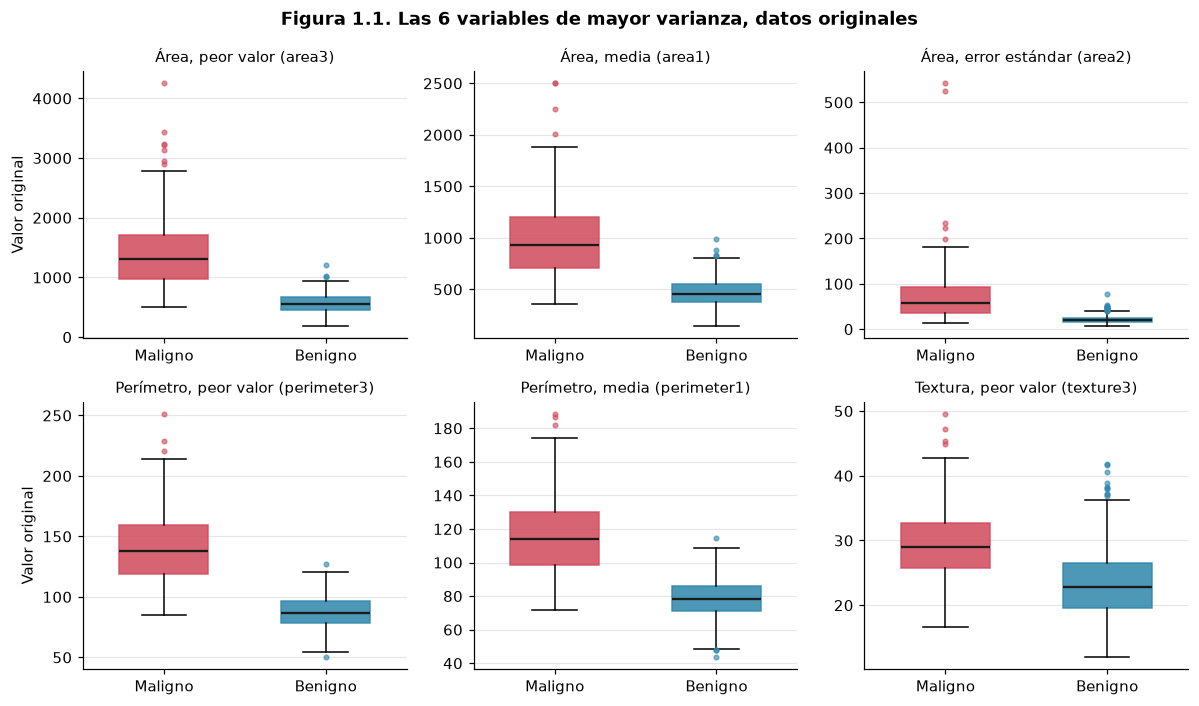

In [8]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Selección de las 6 variables de mayor varianza y sus diagramas de caja.
# Insumo:      X, y.
# Resultado:   top_6, Tabla 1.1 y Figura 1.1.
# ===========================================================
# var() calcula la varianza de cada columna; sort_values las ordena, y ascending=False va de mayor a menor
varianzas = X.var().sort_values(ascending=False)
# head(6) toma las 6 primeras; index son sus nombres; tolist() los convierte en una lista
top_6 = varianzas.head(6).index.tolist()

# X[top_6] conserva solo esas 6 columnas; agg calcula varios estadísticos a la vez.
# .T voltea la tabla (filas por columnas), para tener una variable por fila.
resumen_original = X[top_6].agg(["var", "min", "median", "max"]).T
resumen_original.columns = ["Varianza", "Mínimo", "Mediana", "Máximo"]  # Nombres en español
# Agrega dos columnas: la mediana de esas variables calculada solo con Maligno y solo con Benigno
for clase in COLORES_CLASE:
    resumen_original[f"Mediana {clase}"] = X.loc[y == clase, top_6].median()  # Crea la columna con la mediana de esa clase
print("Tabla 1.1. Las 6 variables originales con mayor varianza")  # Título de la tabla
display(resumen_original.round(2))  # round(2) muestra 2 decimales

# Figura de cajas con los datos originales.
# No se pasa compartir_y, así que vale False: cada panel usa su escala, porque son muy distintas.
graficar_cajas(
    X, top_6, y,  # Datos, variables a dibujar y clases
    "Figura 1.1. Las 6 variables de mayor varianza, datos originales",  # Título
    "Valor original", "figura_1.1_cajas_originales.png",  # Nombre del eje y archivo de la imagen
)  # Cierra la llamada a graficar_cajas

### 1b. Estandarización
`StandardScaler` resta a cada variable su media y la divide entre su desviación estándar, `z = (x - media) / desviación`. Se comprueba que las 30 variables queden con media 0 y desviación 1. `StandardScaler` usa la desviación poblacional (`ddof=0`), así que la comprobación usa la misma.

In [9]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Comprobación de la estandarización de las 30 variables.
# Insumo:      X_std, feature_names.
# Resultado:   X_std_df (X_std con nombres de columna) y Tabla 1.2.
# ===========================================================
# X_std es un arreglo sin nombres de columna; aquí se pasa a tabla para poder usar los nombres
X_std_df = pd.DataFrame(X_std, columns=feature_names)

# Tabla con la media y la desviación estándar de cada variable.
# ddof=0 es la desviación poblacional (divide entre n), la misma que usa StandardScaler.
comprobacion = pd.DataFrame({"Media": X_std_df.mean(), "Desviación estándar": X_std_df.std(ddof=0)})
# allclose comprueba que todos los valores sean casi iguales al indicado; atol es la tolerancia.
# Se usa porque las computadoras redondean: una media puede salir 0.0000000000001 en lugar de 0.
assert np.allclose(comprobacion["Media"], 0, atol=1e-10)  # Todas las medias deben ser 0
assert np.allclose(comprobacion["Desviación estándar"], 1, atol=1e-10)  # Todas las desviaciones deben ser 1

print("Tabla 1.2. Media y desviación estándar de las 30 variables estandarizadas")  # Título
display(comprobacion.round(4) + 0.0)  # Sumar 0.0 convierte -0.0 en 0.0 al mostrar

Tabla 1.2. Media y desviación estándar de las 30 variables estandarizadas


,Media,Desviación estándar
radius1,0.0,1.0
texture1,0.0,1.0
perimeter1,0.0,1.0
area1,0.0,1.0
smoothness1,0.0,1.0
compactness1,0.0,1.0
concavity1,0.0,1.0
concave_points1,0.0,1.0
symmetry1,0.0,1.0
fractal_dimension1,0.0,1.0


### 1c. Las mismas variables, ya estandarizadas
Se usan **las mismas 6 variables del inciso 1a**. Después de estandarizar, las 30 variables tienen la misma varianza, así que ya no se puede volver a elegir por varianza. Conservarlas permite comparar cada variable antes y después. Aquí todos los paneles comparten el eje vertical, porque ya están en la misma escala.

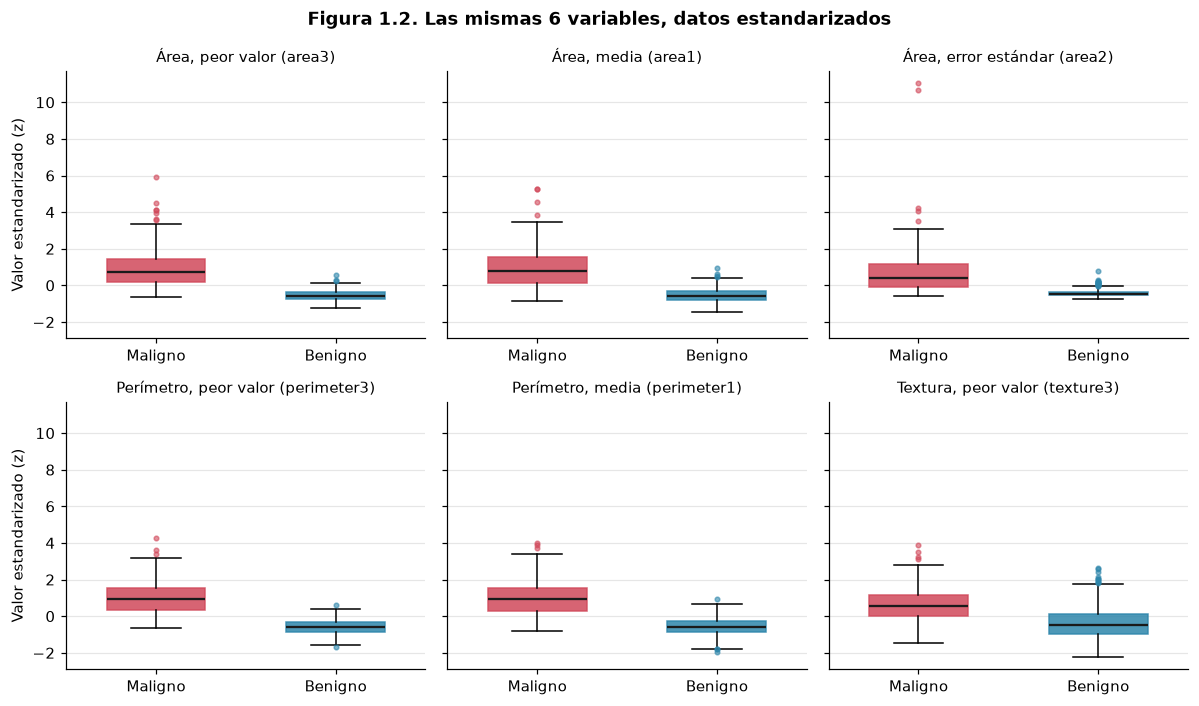

Tabla 1.3. Rango de las 6 variables antes y después de estandarizar


,Rango original,Rango estandarizado,Mínimo estandarizado,Máximo estandarizado
area3,4068.80,7.15,-1.22,5.93
area1,2357.50,6.70,-1.45,5.25
area2,535.40,11.78,-0.74,11.04
perimeter3,200.79,5.98,-1.69,4.29
perimeter1,144.71,5.96,-1.98,3.98
texture3,37.52,6.11,-2.22,3.89


Varianza de area3 entre varianza de la variable con menor varianza (fractal_dimension2): 46,298,438,340 veces
Participación de las 6 variables en la varianza total original: 99.99%


In [10]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Diagramas de caja de las 6 variables estandarizadas y comparación de escalas.
# Insumo:      X_std_df, top_6, y.
# Resultado:   Tabla 1.3 y Figura 1.2.
# ===========================================================
# Misma figura del inciso 1a, con las mismas 6 variables, pero con los datos estandarizados
graficar_cajas(
    X_std_df, top_6, y,  # Ahora usa la tabla estandarizada
    "Figura 1.2. Las mismas 6 variables, datos estandarizados",  # Título
    "Valor estandarizado (z)", "figura_1.2_cajas_estandarizadas.png",  # Nombre del eje y archivo
    compartir_y=True,  # Misma escala en todos los paneles, porque ya son comparables
)  # Cierra la llamada a graficar_cajas

# Compara el rango (máximo menos mínimo) antes y después de estandarizar.
# Cada clave del diccionario es una columna de la tabla.
resumen_escala = pd.DataFrame({
    "Rango original": X[top_6].max() - X[top_6].min(),  # Rango de los datos originales
    "Rango estandarizado": X_std_df[top_6].max() - X_std_df[top_6].min(),  # Rango de los datos estandarizados
    "Mínimo estandarizado": X_std_df[top_6].min(),  # Desviaciones estándar debajo de la media
    "Máximo estandarizado": X_std_df[top_6].max(),  # Desviaciones estándar arriba de la media
})  # Cierra el diccionario y la creación de la tabla
print("Tabla 1.3. Rango de las 6 variables antes y después de estandarizar")  # Título de la tabla
display(resumen_escala.round(2))  # Muestra la tabla con 2 decimales

# Datos para la interpretación del reporte
# iloc toma por posición: iloc[0] es la varianza mayor, e iloc[-1] la menor (la última de la lista).
# ":,.0f" da formato con comas y sin decimales.
print(f"Varianza de area3 entre varianza de la variable con menor varianza ({varianzas.index[-1]}): "
      f"{varianzas.iloc[0] / varianzas.iloc[-1]:,.0f} veces")  # Divide la varianza mayor entre la menor
# Suma de la varianza de las 6 variables entre la de las 30; ":.2%" lo muestra como porcentaje
print(f"Participación de las 6 variables en la varianza total original: {varianzas.head(6).sum() / varianzas.sum():.2%}")

## Sección 2. PCA
**Responsable:** Magaly

_Pendiente: incisos 2a a 2f. Guardar en `k95` el número de componentes que acumulan al menos 95% de la varianza._

## Sección 3. Sammon
### Incisos 3a a 3f
**Responsable:** Ricardo

_Pendiente: Sammon adaptado (con historial de stress), `pca_mas_sammon(X_std, k)` e incisos 3a a 3f. Las celdas de 3g a 3i usan estos nombres:_

- _`pca_mas_sammon(X_std, k)` regresa un diccionario con `t_pca`, `t_sammon`, `t_total`, `Z`, `stress_libreria` y `stress_xstd`._
- _`Z_sammon`: proyección 3D del inciso 3a._
- _`t_sammon_directo`: tiempo total del inciso 3a._
- _`stress_libreria_directo`: stress final que devuelve la librería en el inciso 3a._

### Incisos 3g a 3i. Barrido de k
**Responsable:** Melanie

_Pendiente: se agregan cuando estén los incisos 3a a 3f._

## Sección 4. Autocodificador
**Responsable:** Santiago

_Pendiente: inciso 4a. Antes de ejecutar, fijar la semilla con `tf.keras.utils.set_random_seed(SEED)`._

## Sección 5. Análisis y conclusiones
**Responsable:** Santiago

_Pendiente: incisos 5a y 5b. Completar `comparativa` y volver a exportarla con `exportar_csv(comparativa.reset_index(), "comparativa.csv")`._

## Sección 6. Tablero de resultados
**Responsable:** Magaly

_Pendiente: incisos 6a a 6d._